# SC5002 Lab Assignment Part 2 — Linear vs Ridge Regression on California Housing

This notebook covers Part 2 of the SC5002 lab assignment (Applied ML with AI Copilot). It uses the course's
provided Colab template to predict California house prices from neighbourhood data, compares plain
**Linear Regression** against **Ridge Regression** at three penalty strengths, and charts the results.

The graded template is split into three steps (Tasks 2.1, 2.2 and 2.3), each with a short explanation above it.
An optional extension at the end goes a little further and is clearly marked as not part of the template.

**Open in Colab:** upload this notebook to [Google Colab](https://colab.research.google.com/) (File → Upload notebook)
and choose *Runtime → Run all*. No extra installs are needed; the dataset downloads automatically.

## Task 2.1 — Dataset setup

**What this step does:** it loads the California Housing dataset (census data on California neighbourhoods) and
takes a random sample of 1,000 neighbourhoods so everything runs quickly. It prints the first 5 rows so we can see
what the data looks like (these rows are what gets pasted into the AI tool for Learn-with-AI 2.1).

- **Target (what we predict):** `MedHouseVal`, the median house value in the neighbourhood (in units of $100,000).
- **Inputs (what we predict from):** the other 8 columns, such as median income, house age, rooms, population and location.

**Why the scaling step:** the inputs are on very different scales (for example, population in the thousands vs.
average rooms around 5). `StandardScaler` rescales every input to a common scale (average 0, spread 1) so no feature
dominates just because its numbers are bigger. This matters for Ridge, whose penalty treats all features equally.
Finally the data is split into 80% for training and 20% held back for testing.

The two `pd.set_option` lines are the only addition here: they just make pandas print every column instead of hiding some with `...`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)  # show every column in head()
pd.set_option('display.width', 200)

# --- TASK 2.1: DATASET SETUP ---
print("=== TASK 2.1: Loading California Housing Dataset ===")
housing = fetch_california_housing(as_frame=True)
df = housing.frame.sample(n=1000, random_state=42)  # Sample 1000 records
print("First 5 rows of dataset (Copy these for AI Prompt 2.1):")
print(df.head())

X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

=== TASK 2.1: Loading California Housing Dataset ===
First 5 rows of dataset (Copy these for AI Prompt 2.1):
       MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
20046  1.6812      25.0  4.192201   1.022284      1392.0  3.877437     36.06    -119.01      0.47700
3024   2.5313      30.0  5.039384   1.193493      1565.0  2.679795     35.14    -119.46      0.45800
15663  3.4801      52.0  3.977155   1.185877      1310.0  1.360332     37.80    -122.44      5.00001
20484  5.7376      17.0  6.163636   1.020202      1705.0  3.444444     34.28    -118.72      2.18600
9814   3.7250      34.0  5.492991   1.028037      1063.0  2.483645     36.62    -121.93      2.78000


## Task 2.2 — Model training and cross-validation

**What this step does:** it trains two kinds of model on the training data and scores them.

- **Linear Regression** draws the best straight-line (flat-surface) fit between the inputs and house value.
- **Ridge Regression** is the same idea with a penalty that discourages very large weights on any one input. The
  penalty strength is called **alpha**: small alpha ≈ plain linear regression, large alpha = heavy restraint.
  We try alpha = 0.1, 10 and 1000.

**How it is scored:** 5-fold cross-validation splits the training data into 5 parts, trains on 4 and tests on the
remaining 1, and repeats so each part gets a turn as the test set. The score is **R²**: 1.0 is a perfect prediction,
0 is no better than always guessing the average. Averaging over 5 rounds gives a steadier number than one split.
The individual fold scores are printed as well so the spread is visible (the only addition to the template here).

In [2]:
# --- TASK 2.2: MODEL TRAINING & CROSS-VALIDATION ---
print("=== TASK 2.2: Training Linear Regression ===")
lin_reg = LinearRegression()
lin_scores = cross_val_score(lin_reg, X_train, y_train, cv=5, scoring='r2')
print(f"Linear Regression Mean 5-Fold R2 Score: {lin_scores.mean():.4f}")
print(f"    Fold scores: {np.round(lin_scores, 4)}")

alphas = [0.1, 10.0, 1000.0]
ridge_results = {}
print("--- Training Ridge Regression with Varying Alpha Values ---")
for a in alphas:
    ridge = Ridge(alpha=a)
    scores = cross_val_score(ridge, X_train, y_train, cv=5, scoring='r2')
    ridge_results[a] = scores.mean()
    print(f"Ridge Regression (alpha={a:6.1f}) Mean 5-Fold R2 Score: {scores.mean():.4f}")
    print(f"    Fold scores: {np.round(scores, 4)}")

=== TASK 2.2: Training Linear Regression ===
Linear Regression Mean 5-Fold R2 Score: 0.6457
    Fold scores: [0.7494 0.6018 0.6308 0.6385 0.608 ]
--- Training Ridge Regression with Varying Alpha Values ---
Ridge Regression (alpha=   0.1) Mean 5-Fold R2 Score: 0.6457
    Fold scores: [0.7494 0.6019 0.631  0.6385 0.6079]
Ridge Regression (alpha=  10.0) Mean 5-Fold R2 Score: 0.6443
    Fold scores: [0.7442 0.6032 0.6419 0.6334 0.5989]
Ridge Regression (alpha=1000.0) Mean 5-Fold R2 Score: 0.3574
    Fold scores: [0.4043 0.3384 0.3775 0.3686 0.2983]


## Task 2.3 — Visual comparison

**What this step does:** it draws a bar chart of the average cross-validation R² for each model, so the four
results can be compared at a glance (taller bar = better predictions). The exact score is written on top of each bar.

The only addition is one line that also saves the chart as `model_comparison.png` for use in the report.

=== TASK 2.3: Generating Model Comparison Chart ===


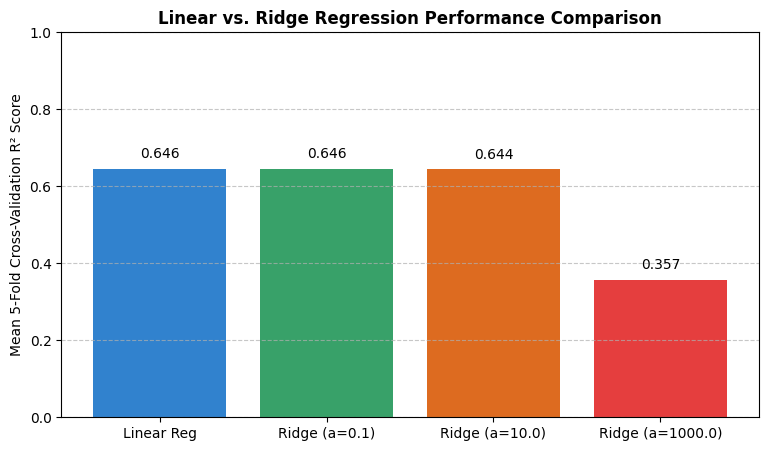

In [3]:
# --- TASK 2.3: VISUALIZATION ---
print("=== TASK 2.3: Generating Model Comparison Chart ===")
plt.figure(figsize=(9, 5))
models = ['Linear Reg'] + [f'Ridge (a={a})' for a in alphas]
scores = [lin_scores.mean()] + list(ridge_results.values())
bars = plt.bar(models, scores, color=['#3182ce', '#38a169', '#dd6b20', '#e53e3e'])
plt.ylabel('Mean 5-Fold Cross-Validation R² Score', fontsize=10)
plt.title('Linear vs. Ridge Regression Performance Comparison', fontsize=12, fontweight='bold')
plt.ylim(0, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.3f}', ha='center', va='bottom')
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Observations

| Model | Mean 5-fold CV R² |
|---|---|
| Linear Regression | 0.6457 |
| Ridge α = 0.1 | 0.6457 |
| Ridge α = 10 | 0.6443 |
| Ridge α = 1000 | 0.3574 |

- **Linear Regression and small-α Ridge perform the same.** All three explain about 64–65% of the variation in house value. The 0.0014 gap between Linear and Ridge α = 10 is far smaller than the difference between folds (fold scores range from about 0.60 to 0.75), so it is effectively a tie.
- **Why Ridge didn't help:** Ridge reduces overfitting, and the plain linear model was not overfitting. Its score on its own training data (0.66, see extension (c)) is almost the same as its cross-validation score (0.65).
- **α = 1000 is too strong, so the model underfits.** The penalty shrinks every coefficient toward zero, so the model ends up close to predicting the average house value for every district. R² falls to 0.36, and the training score is low too (0.40). Both being low is the sign of underfitting rather than overfitting.
- **Cross-validation is more trustworthy than one split.** Each model is tested on 5 different slices of the data. One unlucky or lucky split could have made a model look better or worse than it really is.

---

## Optional extension (not part of graded template)

The cells below go beyond the course template. The headline results above come from the template exactly as given.

### (a) Finer alpha sweep

Instead of only three alpha values, this tries 25 values spread evenly on a log scale from 0.01 to 10,000, using the
same training data and 5-fold cross-validation. The curve shows where the penalty starts to hurt.

Best alpha in sweep: 1.778  (mean CV R2 = 0.6459)
Linear Regression for reference: 0.6457


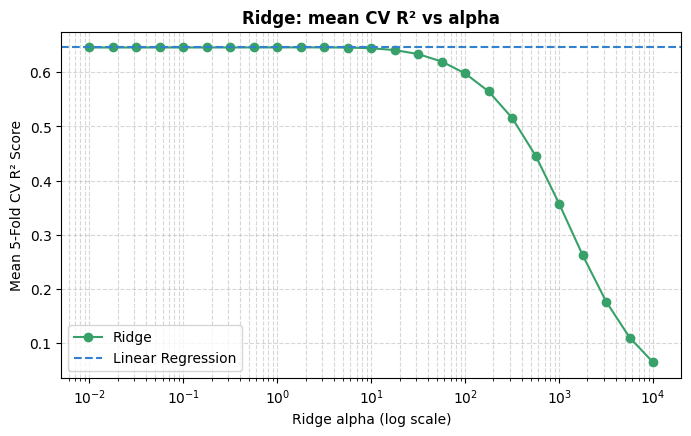

In [4]:
sweep_alphas = np.logspace(-2, 4, 25)
sweep_means = [cross_val_score(Ridge(alpha=a), X_train, y_train, cv=5, scoring='r2').mean() for a in sweep_alphas]
best_i = int(np.argmax(sweep_means))
print(f"Best alpha in sweep: {sweep_alphas[best_i]:.4g}  (mean CV R2 = {sweep_means[best_i]:.4f})")
print(f"Linear Regression for reference: {lin_scores.mean():.4f}")

plt.figure(figsize=(8, 4.5))
plt.semilogx(sweep_alphas, sweep_means, marker='o', color='#38a169', label='Ridge')
plt.axhline(lin_scores.mean(), color='#3182ce', linestyle='--', label='Linear Regression')
plt.xlabel('Ridge alpha (log scale)')
plt.ylabel('Mean 5-Fold CV R² Score')
plt.title('Ridge: mean CV R² vs alpha', fontsize=12, fontweight='bold')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.savefig('alpha_sweep.png', dpi=150, bbox_inches='tight')
plt.show()

### (b) Leakage-free variant

In the template, the scaler is fitted on **all** 1,000 rows before splitting, so the test rows (and each
cross-validation fold's held-out part) slightly influence the scaling. That is a small form of *data leakage*.
Here the scaler and model are bundled in a `Pipeline` and fitted only on the raw training split, so every
cross-validation fold rescales using its own training part only. The template also never uses its 20% test set;
the last line reports the template's linear model on it.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

X_train_raw, X_test_raw, _, _ = train_test_split(X, y, test_size=0.2, random_state=42)
for name, model in [('Linear Regression', LinearRegression()), ('Ridge (alpha=10)', Ridge(alpha=10.0))]:
    pipe = Pipeline([('scaler', StandardScaler()), ('model', model)])
    s = cross_val_score(pipe, X_train_raw, y_train, cv=5, scoring='r2')
    print(f"Leakage-free {name:<18} Mean 5-Fold R2 Score: {s.mean():.4f}")

lin_reg.fit(X_train, y_train)
print(f"Template Linear Regression held-out test R2: {r2_score(y_test, lin_reg.predict(X_test)):.4f}")

Leakage-free Linear Regression  Mean 5-Fold R2 Score: 0.6457
Leakage-free Ridge (alpha=10)   Mean 5-Fold R2 Score: 0.6443
Template Linear Regression held-out test R2: 0.6619


### (c) Train vs cross-validation R² (under- vs overfitting check)

If a model **overfits**, it scores much higher on the data it trained on than in cross-validation. If it **underfits**, both scores are low and close together.

In [6]:
rows = []
for name, model in [('Linear Reg', LinearRegression())] + [(f'Ridge (a={a})', Ridge(alpha=a)) for a in alphas]:
    cv = cross_val_score(model, X_train, y_train, cv=5, scoring='r2')
    train_r2 = model.fit(X_train, y_train).score(X_train, y_train)
    rows.append({'Model': name, 'CV mean R2': cv.mean(), 'CV std': cv.std(), 'Train R2': train_r2})
print(pd.DataFrame(rows).round(4).to_string(index=False))

           Model  CV mean R2  CV std  Train R2
      Linear Reg      0.6457  0.0536    0.6617
   Ridge (a=0.1)      0.6457  0.0536    0.6617
  Ridge (a=10.0)      0.6443  0.0526    0.6599
Ridge (a=1000.0)      0.3574  0.0363    0.4030
